## Load Predictions & Split Benchmarks

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

PHASE2_ROOT = Path.cwd().resolve().parent
if str(PHASE2_ROOT) not in sys.path:
    sys.path.insert(0, str(PHASE2_ROOT))

from src.paths import FIGURES_DIR, PREDICTIONS_PARQUET, SELECTED_6_GENRES, ensure_dirs

ensure_dirs()
plt.rcParams["figure.dpi"] = 140

df = pd.read_parquet(PREDICTIONS_PARQUET)
df_6 = df[df["benchmark"] == "6genre_p1_exact"].copy()
df_30 = df[df["benchmark"] == "30genre_test"].copy()

print(f"Loaded {len(df):,} rows | 6-genre: {len(df_6):,} | 30-genre: {len(df_30):,}")

Loaded 6,000 rows | 6-genre: 3,000 | 30-genre: 3,000


## Per-Genre OCR Reliance & Prompt-Ladder Chart

,Genre,Orig L2 (%),Masked L2 (%),OCR Drop L2 (pp),Orig L4 (%),Masked L4 (%),Mean Text Area (%)
5,Children's Books,65.0,53.2,11.8,78.0,71.6,17.6
2,Science Fiction & Fantasy,45.0,35.2,9.8,45.8,41.2,18.3
3,History,49.4,40.8,8.6,74.0,63.4,17.9
4,Biographies & Memoirs,65.0,57.6,7.4,50.8,50.0,21.3
1,"Mystery, Thriller & Suspense",71.8,67.2,4.6,56.2,56.2,34.4
0,Romance,70.4,68.4,2.0,62.2,63.6,24.2


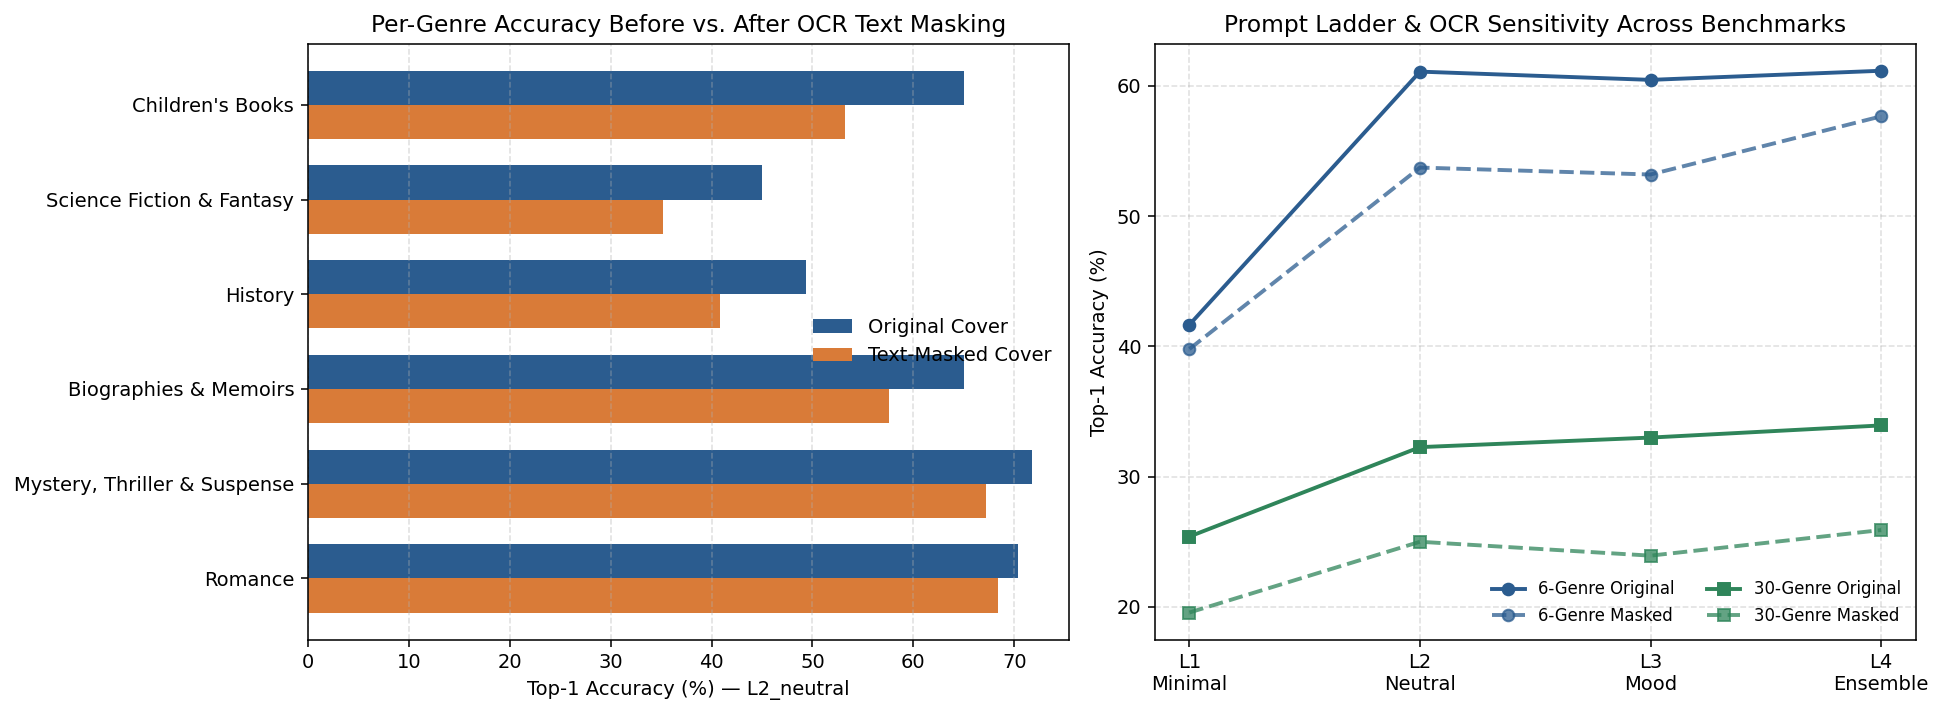

In [2]:
genre_rows = []
for genre in SELECTED_6_GENRES:
    sub = df_6[df_6["genre"] == genre]
    orig_l2 = (sub["orig_L2_neutral_pred"] == genre).mean() * 100
    mask_l2 = (sub["mask_L2_neutral_pred"] == genre).mean() * 100
    orig_l4 = (sub["orig_L4_prompt_ensemble_pred"] == genre).mean() * 100
    mask_l4 = (sub["mask_L4_prompt_ensemble_pred"] == genre).mean() * 100
    genre_rows.append(
        {
            "Genre": genre,
            "Orig L2 (%)": round(orig_l2, 2),
            "Masked L2 (%)": round(mask_l2, 2),
            "OCR Drop L2 (pp)": round(orig_l2 - mask_l2, 2),
            "Orig L4 (%)": round(orig_l4, 2),
            "Masked L4 (%)": round(mask_l4, 2),
            "Mean Text Area (%)": round(sub["text_area_ratio"].mean() * 100, 1),
        }
    )

df_genre_ocr = pd.DataFrame(genre_rows).sort_values("OCR Drop L2 (pp)", ascending=False)
display(df_genre_ocr)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# Left: Per-genre Original vs Text-Masked accuracy (L2_neutral)
y = np.arange(len(df_genre_ocr))
h = 0.36
axes[0].barh(y - h / 2, df_genre_ocr["Orig L2 (%)"], height=h, label="Original Cover", color="#2b5c8f")
axes[0].barh(y + h / 2, df_genre_ocr["Masked L2 (%)"], height=h, label="Text-Masked Cover", color="#d97b38")
axes[0].set_yticks(y)
axes[0].set_yticklabels(df_genre_ocr["Genre"])
axes[0].invert_yaxis()
axes[0].set_xlabel("Top-1 Accuracy (%) — L2_neutral")
axes[0].set_title("Per-Genre Accuracy Before vs. After OCR Text Masking")
axes[0].legend(frameon=False)
axes[0].grid(axis="x", linestyle="--", alpha=0.4)

# Right: Prompt Ladder Comparison (Original vs Masked across both benchmarks)
levels = ["L1_minimal", "L2_neutral", "L3_stylistic_mood", "L4_prompt_ensemble"]
short_labels = ["L1\nMinimal", "L2\nNeutral", "L3\nMood", "L4\nEnsemble"]
x = np.arange(len(levels))

acc_6_orig = [(df_6[f"orig_{lvl}_pred"] == df_6["genre"]).mean() * 100 for lvl in levels]
acc_6_mask = [(df_6[f"mask_{lvl}_pred"] == df_6["genre"]).mean() * 100 for lvl in levels]
acc_30_orig = [(df_30[f"orig_{lvl}_pred"] == df_30["genre"]).mean() * 100 for lvl in levels]
acc_30_mask = [(df_30[f"mask_{lvl}_pred"] == df_30["genre"]).mean() * 100 for lvl in levels]

axes[1].plot(x, acc_6_orig, marker="o", lw=2, color="#2b5c8f", label="6-Genre Original")
axes[1].plot(x, acc_6_mask, marker="o", lw=2, ls="--", color="#2b5c8f", alpha=0.75, label="6-Genre Masked")
axes[1].plot(x, acc_30_orig, marker="s", lw=2, color="#2f855a", label="30-Genre Original")
axes[1].plot(x, acc_30_mask, marker="s", lw=2, ls="--", color="#2f855a", alpha=0.75, label="30-Genre Masked")
axes[1].set_xticks(x)
axes[1].set_xticklabels(short_labels)
axes[1].set_ylabel("Top-1 Accuracy (%)")
axes[1].set_title("Prompt Ladder & OCR Sensitivity Across Benchmarks")
axes[1].legend(frameon=False, ncol=2, fontsize=8.5)
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "fig1_ocr_and_prompt_sensitivity.png", bbox_inches="tight")
plt.show()

## Visual Stereotype Amplification

,Predicted Genre,Feature,TP Mean,FP Mean (Stereotype Pull),Other Mean,FP Z-Shift,p-value
4,"Mystery, Thriller & Suspense",Brightness,0.526,0.484,0.580,-0.52,0.0000
7,"Mystery, Thriller & Suspense",Face Area Ratio,0.002,0.004,0.010,-0.17,0.0000
16,Biographies & Memoirs,Brightness,0.563,0.595,0.551,0.23,0.0000
19,Biographies & Memoirs,Face Area Ratio,0.028,0.015,0.004,0.46,0.0000
20,Children's Books,Brightness,0.707,0.625,0.533,0.49,0.0000
13,History,Saturation,0.315,0.335,0.393,-0.31,0.0002
17,Biographies & Memoirs,Saturation,0.305,0.365,0.400,-0.18,0.0008
9,Science Fiction & Fantasy,Saturation,0.420,0.455,0.376,0.42,0.0016
14,History,Warm Hue Ratio,0.340,0.430,0.359,0.25,0.0044
5,"Mystery, Thriller & Suspense",Saturation,0.439,0.398,0.367,0.17,0.0060


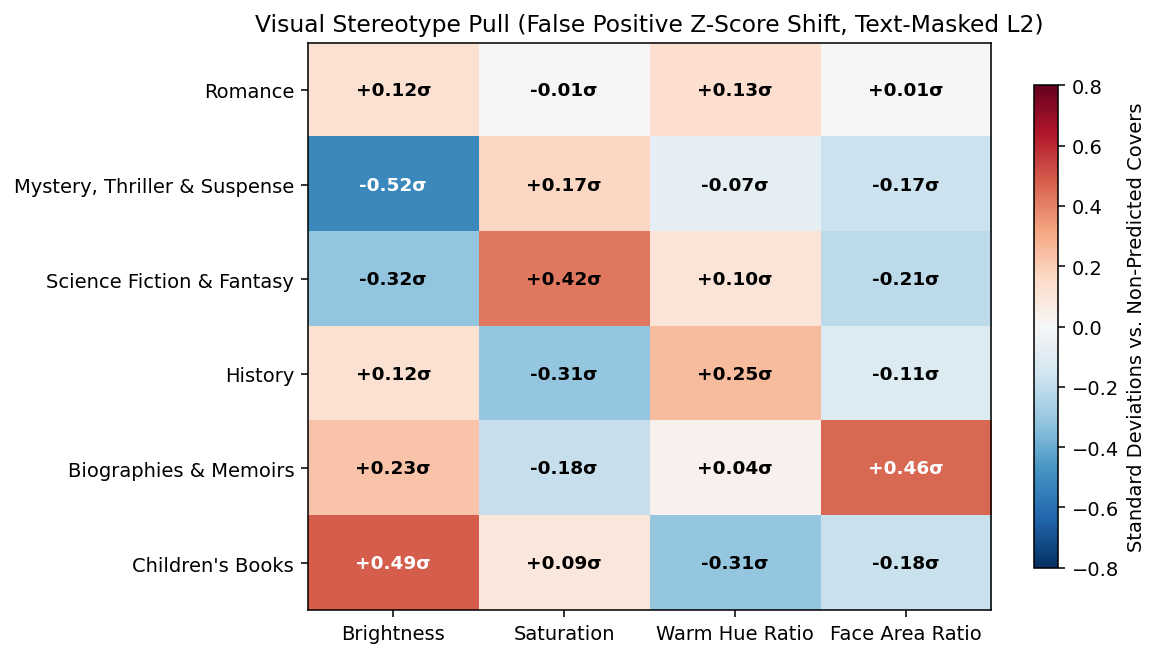

In [3]:
# Compare visual attributes of False Positives (covers wrongly pulled into a genre)
# vs. True Positives and the overall dataset using text-masked predictions (pure visual signal)
FEATURES = ["mean_brightness", "mean_saturation", "warm_pixel_ratio", "face_area_ratio"]
FEATURE_LABELS = ["Brightness", "Saturation", "Warm Hue Ratio", "Face Area Ratio"]

stereotype_rows = []
z_matrix = np.zeros((len(SELECTED_6_GENRES), len(FEATURES)))

for i, genre in enumerate(SELECTED_6_GENRES):
    is_true = df_6["genre"] == genre
    is_pred = df_6["mask_L2_neutral_pred"] == genre

    tp = df_6[is_true & is_pred]
    fp = df_6[~is_true & is_pred]
    rest = df_6[~is_true & ~is_pred]

    for j, feat in enumerate(FEATURES):
        fp_mean = fp[feat].mean()
        tp_mean = tp[feat].mean()
        rest_mean = rest[feat].mean()
        rest_std = rest[feat].std() + 1e-8
        z_shift = (fp_mean - rest_mean) / rest_std
        z_matrix[i, j] = z_shift

        _, p_val = stats.mannwhitneyu(fp[feat], rest[feat], alternative="two-sided")
        stereotype_rows.append(
            {
                "Predicted Genre": genre,
                "Feature": FEATURE_LABELS[j],
                "TP Mean": round(tp_mean, 3),
                "FP Mean (Stereotype Pull)": round(fp_mean, 3),
                "Other Mean": round(rest_mean, 3),
                "FP Z-Shift": round(z_shift, 2),
                "p-value": round(p_val, 4),
            }
        )

df_stereo = pd.DataFrame(stereotype_rows)
display(df_stereo[df_stereo["p-value"] < 0.05].sort_values("p-value"))

fig, ax = plt.subplots(figsize=(8.5, 4.8))
im = ax.imshow(z_matrix, cmap="RdBu_r", vmin=-0.8, vmax=0.8, aspect="auto")

ax.set_xticks(np.arange(len(FEATURE_LABELS)))
ax.set_xticklabels(FEATURE_LABELS)
ax.set_yticks(np.arange(len(SELECTED_6_GENRES)))
ax.set_yticklabels(SELECTED_6_GENRES)
ax.set_title("Visual Stereotype Pull (False Positive Z-Score Shift, Text-Masked L2)")

for i in range(len(SELECTED_6_GENRES)):
    for j in range(len(FEATURES)):
        val = z_matrix[i, j]
        color = "white" if abs(val) > 0.45 else "black"
        ax.text(j, i, f"{val:+.2f}σ", ha="center", va="center", color=color, fontsize=9.5, fontweight="bold")

cbar = fig.colorbar(im, ax=ax, shrink=0.85)
cbar.set_label("Standard Deviations vs. Non-Predicted Covers")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "fig2_visual_stereotypes.png", bbox_inches="tight")
plt.show()

## Margin Calibration & Before/After Text-Masking Confusion Matrices

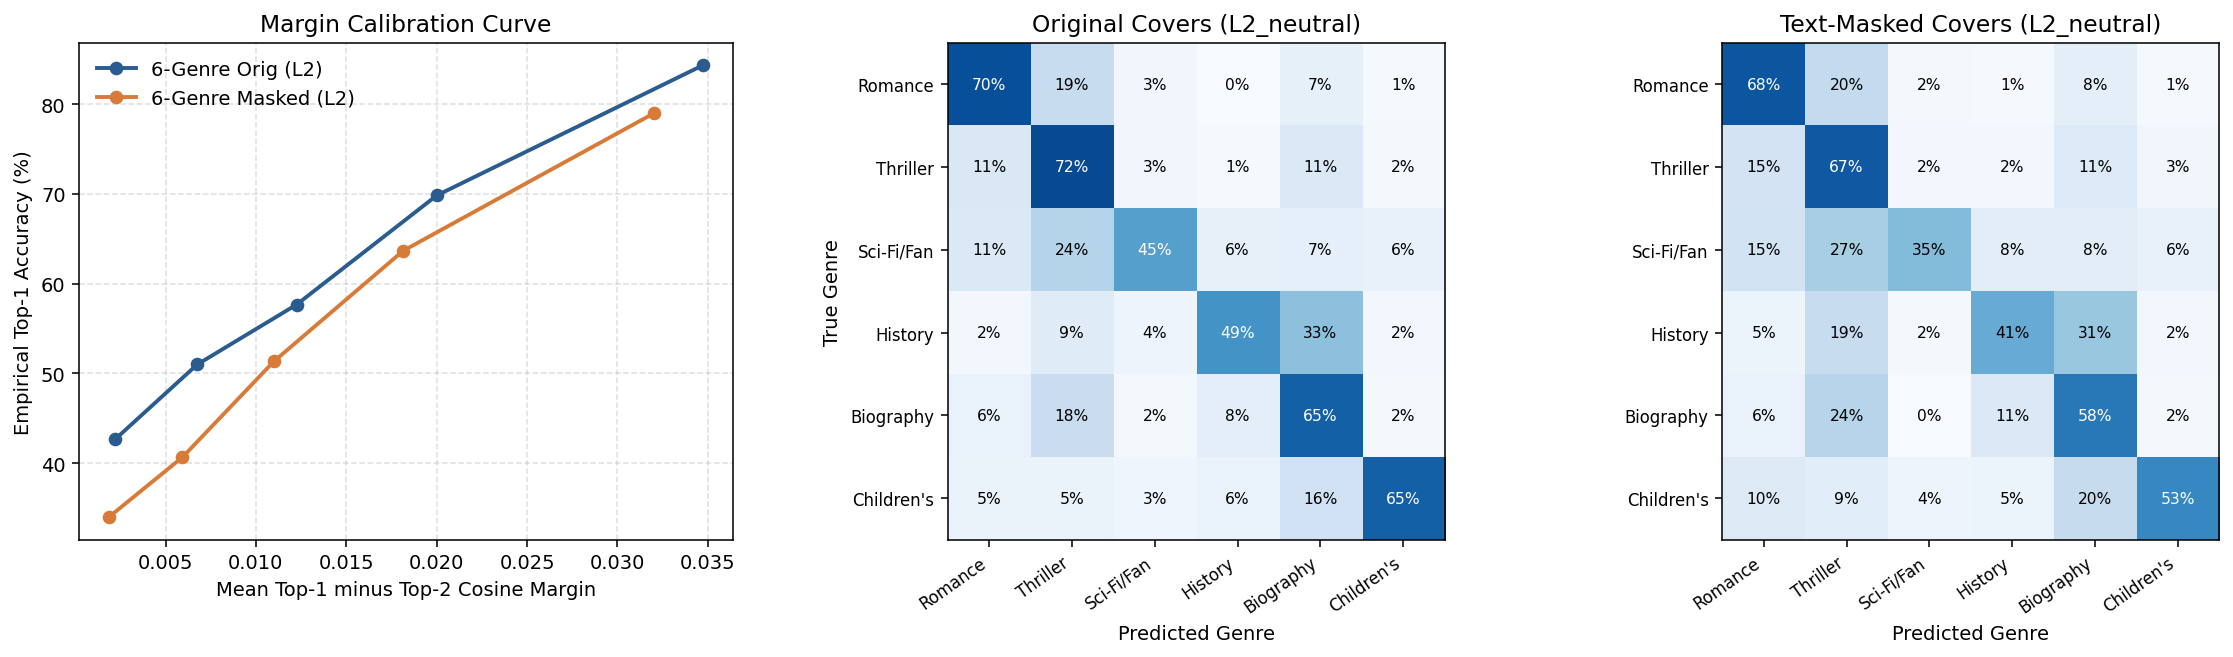

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8), gridspec_kw={"width_ratios": [1.05, 1, 1]})

# Panel 1: Calibration curve (Margin quintiles vs Empirical Accuracy)
for label, prefix, color in [
    ("6-Genre Orig (L2)", "orig_L2_neutral", "#2b5c8f"),
    ("6-Genre Masked (L2)", "mask_L2_neutral", "#d97b38"),
]:
    bins = pd.qcut(df_6[f"{prefix}_margin"], q=5, duplicates="drop")
    cal = (
        df_6.assign(
            margin_bin=bins,
            correct=(df_6[f"{prefix}_pred"] == df_6["genre"]).astype(float),
        )
        .groupby("margin_bin", observed=False)
        .agg(mean_margin=(f"{prefix}_margin", "mean"), acc=("correct", "mean"))
    )
    axes[0].plot(cal["mean_margin"], cal["acc"] * 100, marker="o", lw=2, color=color, label=label)

axes[0].set_xlabel("Mean Top-1 minus Top-2 Cosine Margin")
axes[0].set_ylabel("Empirical Top-1 Accuracy (%)")
axes[0].set_title("Margin Calibration Curve")
axes[0].legend(frameon=False)
axes[0].grid(True, linestyle="--", alpha=0.4)

# Panels 2 & 3: Row-normalized Confusion Matrices (Original vs Masked)
short_genres = ["Romance", "Thriller", "Sci-Fi/Fan", "History", "Biography", "Children's"]
for ax, col_name, title in [
    (axes[1], "orig_L2_neutral_pred", "Original Covers (L2_neutral)"),
    (axes[2], "mask_L2_neutral_pred", "Text-Masked Covers (L2_neutral)"),
]:
    cm = pd.crosstab(
        pd.Categorical(df_6["genre"], categories=SELECTED_6_GENRES),
        pd.Categorical(df_6[col_name], categories=SELECTED_6_GENRES),
        normalize="index",
    ).to_numpy() * 100

    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=80)
    ax.set_xticks(np.arange(len(short_genres)))
    ax.set_xticklabels(short_genres, rotation=35, ha="right", fontsize=8.5)
    ax.set_yticks(np.arange(len(short_genres)))
    ax.set_yticklabels(short_genres, fontsize=8.5)
    ax.set_xlabel("Predicted Genre")
    ax.set_title(title)
    if ax is axes[1]:
        ax.set_ylabel("True Genre")

    for r in range(len(short_genres)):
        for c in range(len(short_genres)):
            val = cm[r, c]
            ax.text(c, r, f"{val:.0f}%", ha="center", va="center", color="white" if val > 42 else "black", fontsize=8)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "fig3_calibration_and_confusion.png", bbox_inches="tight")
plt.show()